# Survival analysis and robustness

**Name:** Raaj Banga

Time to recovery, capped at the same length for every crash. Needs the archetypes saved by notebook 03.

## Part 1: Setup

### Block 1: Imports and paths

In [1]:
# python 3.14.10, pandas 2.3.3, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1, matplotlib 3.11.2, lifelines 0.30.3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lifelines import AalenJohansenFitter, CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test, pairwise_logrank_test, proportional_hazard_test
import importlib
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

# Find the project folder whether this runs from notebooks/ or the project root
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
from config import CRASHES, INTERIM, PROCESSED, SEED, SURVIVAL_CAP_MONTHS
from helpers import (FEATURES, Winsorizer, make_model, model_columns, CRASH_COLORS, CRASH_LABELS, CRASH_SHORT, load_firms, save_figure, set_style)

set_style()
import warnings
warnings.filterwarnings("ignore", message=".*feature names.*")
warnings.filterwarnings("ignore", message=".*generic.*unit.*")
ORDER = list(CRASHES)

### Block 2: Load the data

In [2]:
# One row per firm per crash, from 07_build_features.py
firms = load_firms()
print(firms.shape)
print(firms["crash"].value_counts().to_string())

# Archetypes saved by notebook 03 (Block 8)
archetypes = pd.read_parquet(PROCESSED / "archetypes.parquet")
firms = firms.merge(archetypes, on=["cik", "crash"], how="left")
assert firms["archetype"].notna().all()

(10513, 70)
crash
tariff_2025    3698
rates_2022     3599
covid_2020     3216


## Part 2: Survival analysis

### Block 3: Handle exits

Decided 2026-11-08:
- **Main analysis:** the labels as built in `06`. Recovery is the event, with time counted from the trough and capped at 18 months.
  - Failed firms never recover: they are censored at the cap with no event.
  - Acquired firms, other delistings, and rows whose prices stop are censored at their last trade.
- **Check:** competing risks. Failure becomes its own event, at its filing date, and Aalen-Johansen gives the cumulative incidence of recovery while accounting for it.

In [3]:
cap_days = firms["crash"].map(lambda c: (pd.Timestamp(CRASHES[c]["trough"]) + pd.DateOffset(months=SURVIVAL_CAP_MONTHS)
                                         - pd.Timestamp(CRASHES[c]["trough"])).days)
firms["T"] = firms["recovery_days"].clip(lower=0.5)   # day 0 recoveries need a positive time
firms["E"] = firms["recovered_event"]

# Competing risks: 1 = recovered, 2 = failed before recovering, 0 = censored
trough = firms["crash"].map(lambda c: pd.Timestamp(CRASHES[c]["trough"]))
failed_first = (firms["exit_status"] == "failed") & (firms["E"] == 0)
firms["cr_event"] = np.where(firms["E"] == 1, 1, np.where(failed_first, 2, 0))
firms["cr_T"] = np.where(failed_first, (firms["exit_date"] - trough).dt.days.clip(lower=0.5), firms["T"])

table = pd.crosstab(firms["exit_status"], [firms["crash"], firms["E"]]).rename(columns=CRASH_SHORT, level=0)
print("Rows by exit status, crash, and recovery event (1 = recovered within 18 months):")
print(table.to_string())
print("\nCompeting-risk events:", pd.crosstab(firms["cr_event"], firms["crash"]).rename(columns=CRASH_SHORT).to_string(), sep="\n")

Rows by exit status, crash, and recovery event (1 = recovered within 18 months):
crash          2020        2022       2025      
E                 0     1     0     1    0     1
exit_status                                     
acquired         46    93   124    73   68   129
delisted_other    7     5    11     3    3     8
failed           21     2    47     2   18     3
none            484  2558  1656  1683  814  2655

Competing-risk events:
crash     2020  2022  2025
cr_event                  
0          537  1791   885
1         2658  1761  2795
2           21    47    18


### Block 4: Kaplan-Meier by crash

Share of firms back at their pre-crash price by each day after the trough (1 minus the survival curve). Log-rank tests compare the crashes. Then the competing-risk version of the same curves.

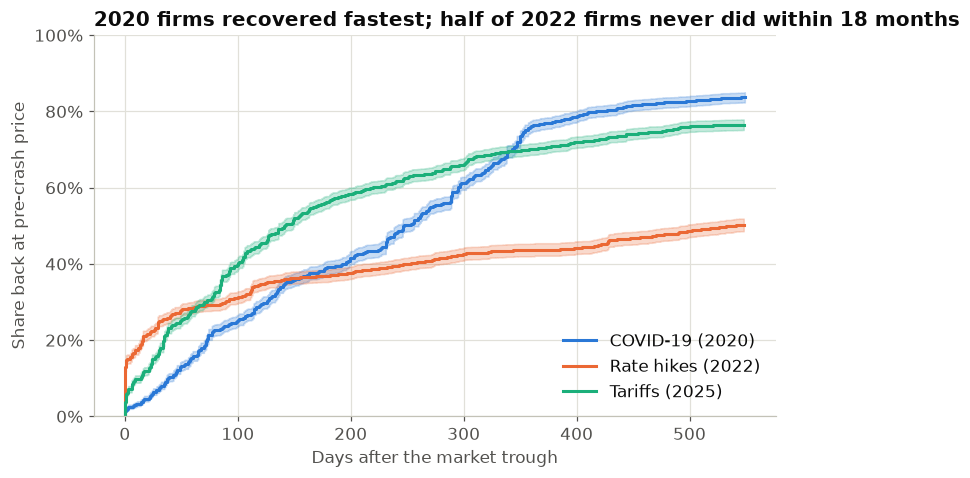

crash  median days to recovery  KM recovered by 6 mo  KM by 12 mo  KM by 18 mo  AJ recovered by 12 mo  AJ failed by 12 mo
 2020                    247.0                 0.391        0.765        0.837                  0.765               0.007
 2022                    539.0                 0.370        0.438        0.502                  0.439               0.008
 2025                    142.0                 0.568        0.702        0.765                  0.702               0.004



Log-rank across crashes: chi2 = 572.2, p = 5.5e-125
                        test_statistic       p  -log2(p)
covid_2020 rates_2022         471.2129  0.0000  344.6771
           tariff_2025          3.3416  0.0676    3.8879
rates_2022 tariff_2025        389.2838  0.0000  285.4407


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
km_rows = []
for crash in ORDER:
    d = firms[firms["crash"] == crash]
    km = KaplanMeierFitter().fit(d["T"], d["E"], label=CRASH_LABELS[crash])
    km.plot_cumulative_density(ax=ax, color=CRASH_COLORS[crash], ci_show=True)
    aj = AalenJohansenFitter(calculate_variance=False, seed=SEED).fit(d["cr_T"], d["cr_event"], event_of_interest=1)
    aj_fail = AalenJohansenFitter(calculate_variance=False, seed=SEED).fit(d["cr_T"], d["cr_event"], event_of_interest=2)
    at = lambda f, t: float(f.cumulative_density_.loc[:t].iloc[-1, 0])
    km_rows.append({"crash": CRASH_SHORT[crash], "median days to recovery": km.median_survival_time_,
                    "KM recovered by 6 mo": 1 - km.predict(182), "KM by 12 mo": 1 - km.predict(365),
                    "KM by 18 mo": 1 - km.predict(cap_days[d.index[0]]),
                    "AJ recovered by 12 mo": at(aj, 365), "AJ failed by 12 mo": at(aj_fail, 365)})
ax.set_xlabel("Days after the market trough")
ax.set_ylabel("Share back at pre-crash price")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylim(0, 1)
ax.set_title("2020 firms recovered fastest; half of 2022 firms never did within 18 months")
ax.legend(loc="lower right")
save_figure(fig, "km_by_crash")
plt.show()

print(pd.DataFrame(km_rows).round(3).to_string(index=False))
lr = multivariate_logrank_test(firms["T"], firms["crash"], firms["E"])
print(f"\nLog-rank across crashes: chi2 = {lr.test_statistic:.1f}, p = {lr.p_value:.2g}")
print(pairwise_logrank_test(firms["T"], firms["crash"], firms["E"]).summary.round(4).to_string())

### Block 5: Kaplan-Meier by archetype

One panel per crash, one curve per archetype from notebook 03. A log-rank test within each crash asks whether archetypes recover at different speeds.

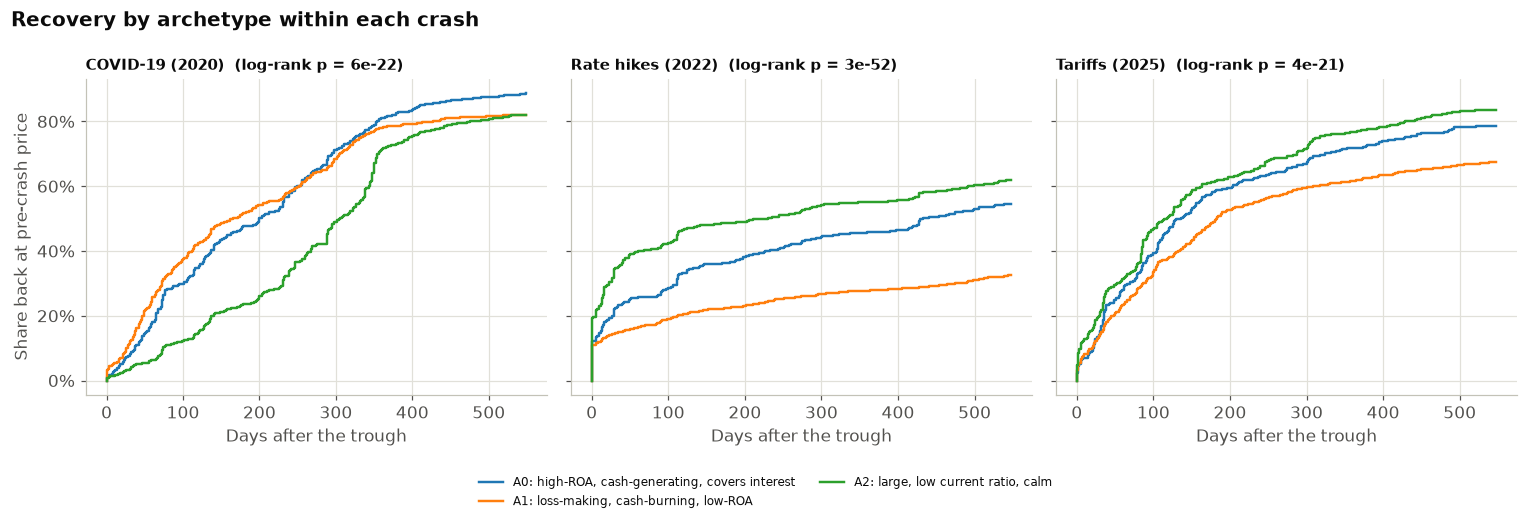

crash                                      archetype    n  median days  recovered by 12 mo
 2020 A0: high-ROA, cash-generating, covers interest  807        199.0               0.814
 2020         A1: loss-making, cash-burning, low-ROA 1079        164.0               0.783
 2020             A2: large, low current ratio, calm 1330        305.0               0.719
 2022 A0: high-ROA, cash-generating, covers interest  828        433.0               0.457
 2022         A1: loss-making, cash-burning, low-ROA 1219          inf               0.280
 2022             A2: large, low current ratio, calm 1552        230.0               0.552
 2025 A0: high-ROA, cash-generating, covers interest  910        136.0               0.718
 2025         A1: loss-making, cash-burning, low-ROA 1323        183.0               0.618
 2025             A2: large, low current ratio, calm 1465        118.0               0.767


In [5]:
names = firms.drop_duplicates("archetype").set_index("archetype")["archetype_name"].sort_index()
palette = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
arch_rows = []
for ax, crash in zip(axes, ORDER):
    d = firms[firms["crash"] == crash]
    for a, name in names.items():
        g = d[d["archetype"] == a]
        km = KaplanMeierFitter().fit(g["T"], g["E"], label=name)
        km.plot_cumulative_density(ax=ax, ci_show=False, color=palette(a), linewidth=1.6)
        arch_rows.append({"crash": CRASH_SHORT[crash], "archetype": name, "n": len(g),
                          "median days": km.median_survival_time_, "recovered by 12 mo": 1 - km.predict(365)})
    test = multivariate_logrank_test(d["T"], d["archetype"], d["E"])
    ax.set_title(f"{CRASH_LABELS[crash]}  (log-rank p = {test.p_value:.1g})", fontsize=10)
    ax.set_xlabel("Days after the trough")
    ax.get_legend().remove()
axes[0].set_ylabel("Share back at pre-crash price")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Recovery by archetype within each crash", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "km_by_archetype")
plt.show()
print(pd.DataFrame(arch_rows).round(3).to_string(index=False))

### Block 6: Cox proportional hazards

Recovery is the event, so a hazard ratio above 1 means faster recovery.
- Features are capped at their 1st and 99th percentiles, filled with the median, and standardized within each crash, so each hazard ratio is per one standard deviation in that crash.
- One pooled model is stratified by crash, with robust standard errors grouped by firm, since firms repeat. Then one model per crash shows which effects flip.
- A small ridge penalty (0.01) keeps the fit stable.

Pooled model, stratified by crash: concordance 0.560
                       exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                        
current_ratio              1.036                1.006                1.067  0.020
cash_to_assets             1.036                1.002                1.072  0.037
debt_to_assets             0.961                0.937                0.985  0.002
liabilities_to_assets      1.035                1.002                1.070  0.036
interest_coverage          0.997                0.969                1.025  0.818
net_margin                 0.974                0.912                1.040  0.431
operating_margin           1.009                0.945                1.078  0.793
return_on_assets           1.005                0.952                1.062  0.854
ocf_to_assets              1.050                0.996                1.107  0.069
revenue_growth             1.002             


Hazard ratio per 1 SD, by crash (* p < 0.05):
                        2020   2022   2025
covariate                                 
current_ratio           1.0   0.98   1.08*
cash_to_assets         1.07*  0.95   1.03 
debt_to_assets         0.93*  0.98   0.96*
liabilities_to_assets  1.02   0.98   1.07*
interest_coverage      0.99   1.01   0.99 
net_margin             1.06   0.95   0.93 
operating_margin       0.96   1.04   1.03 
return_on_assets       1.05   0.86*  1.16*
ocf_to_assets          1.04   1.21*  0.91 
revenue_growth         1.03   0.96   0.99 
asset_growth           1.03   0.83*  1.02 
log_assets             0.78*  1.42*  1.13*
log_market_value       1.26*  0.78*   1.0 
volatility_12m         1.03   0.72*  0.84*
momentum_12_1          1.07*  1.08*  1.09*
beta                   1.09*  0.93*  0.99 
is_financial            0.8*  0.62*  1.17*

Significant in at least two crashes but in opposite directions: ['return_on_assets', 'log_assets', 'log_market_value', 'beta', 'is_fina

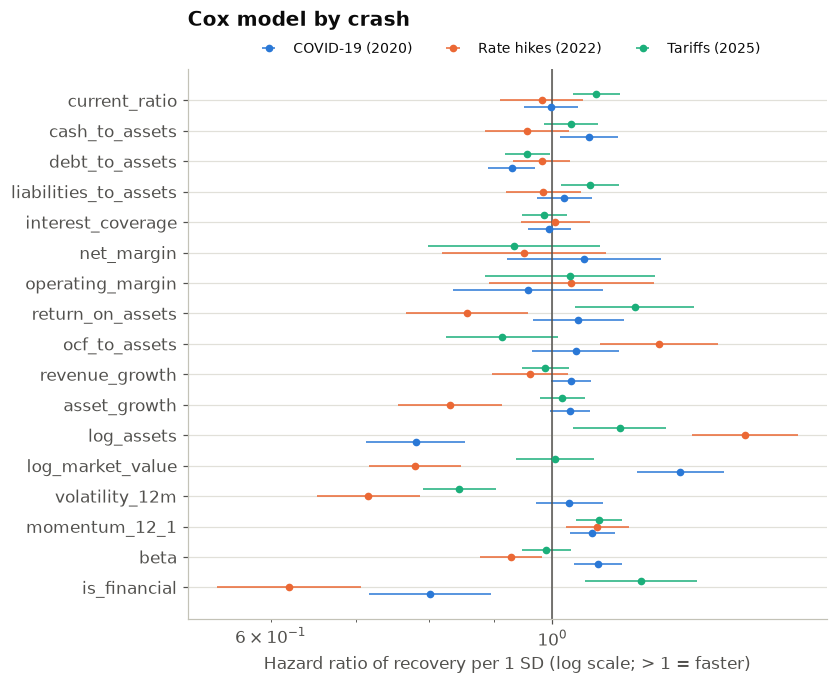

In [6]:
def cox_frame(d):
    X = pd.DataFrame(Winsorizer().fit_transform(d[FEATURES]), columns=FEATURES, index=d.index)
    X = X.fillna(X.median())
    X = (X - X.mean()) / X.std()
    return X.assign(is_financial=d["is_financial"].values, T=d["T"].values, E=d["E"].values)

pooled = pd.concat([cox_frame(firms[firms["crash"] == c]).assign(crash=c, cik=firms.loc[firms["crash"] == c, "cik"])
                    for c in ORDER])
cph = CoxPHFitter(penalizer=0.01).fit(pooled, "T", "E", strata=["crash"], cluster_col="cik")
print(f"Pooled model, stratified by crash: concordance {cph.concordance_index_:.3f}")
print(cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3).to_string())

per_crash, fits = {}, {}
for crash in ORDER:
    df = cox_frame(firms[firms["crash"] == crash])
    fits[crash] = (CoxPHFitter(penalizer=0.01).fit(df, "T", "E"), df)
    per_crash[crash] = fits[crash][0].summary
hr = pd.DataFrame({CRASH_SHORT[c]: per_crash[c]["exp(coef)"] for c in ORDER})
pv = pd.DataFrame({CRASH_SHORT[c]: per_crash[c]["p"] for c in ORDER})
print("\nHazard ratio per 1 SD, by crash (* p < 0.05):")
print((hr.round(2).astype(str) + np.where(pv < 0.05, "*", " ")).to_string())
sig = (pv < 0.05)
flips = [f for f in hr.index if sig.loc[f].sum() >= 2 and (np.sign(np.log(hr.loc[f][sig.loc[f]])).nunique() > 1)]
print("\nSignificant in at least two crashes but in opposite directions:", flips)
print("Concordance by crash:", {CRASH_SHORT[c]: round(fits[c][0].concordance_index_, 3) for c in ORDER})

fig, ax = plt.subplots(figsize=(7.5, 6.5))
feats = hr.index[::-1]
for k, crash in enumerate(ORDER):
    s = per_crash[crash].loc[feats]
    y = np.arange(len(feats)) + (k - 1) * 0.22
    ax.errorbar(s["exp(coef)"], y, xerr=[s["exp(coef)"] - s["exp(coef) lower 95%"], s["exp(coef) upper 95%"] - s["exp(coef)"]],
                fmt="o", color=CRASH_COLORS[crash], label=CRASH_LABELS[crash], markersize=4, linewidth=1)
ax.axvline(1, color="#52514e", linewidth=1)
ax.set_xscale("log")
ax.set_yticks(np.arange(len(feats)), feats)
ax.set_xlabel("Hazard ratio of recovery per 1 SD (log scale; > 1 = faster)")
ax.grid(axis="x", color="#e1e0d9")
ax.set_title("Cox model by crash", pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=9)
save_figure(fig, "cox_hazard_ratios")
plt.show()

### Block 7: Proportional hazards check

Schoenfeld residual test (rank time transform) per crash. A small p-value means the feature's effect changes over the 18 months, so its hazard ratio is an average over time.

In [7]:
ph = {}
for crash in ORDER:
    model, df = fits[crash]
    ph[CRASH_SHORT[crash]] = proportional_hazard_test(model, df, time_transform="rank").summary["p"]
ph = pd.DataFrame(ph)
print(ph.round(4).to_string())
print("\nFeatures failing the check (p < 0.05) per crash:", (ph < 0.05).sum().to_dict())

                         2020    2022    2025
asset_growth           0.1100  0.0388  0.1784
beta                   0.0000  0.0000  0.0000
cash_to_assets         0.4518  0.0029  0.3322
current_ratio          0.0039  0.7221  0.0001
debt_to_assets         0.0895  0.4950  0.0152
interest_coverage      0.8599  0.5958  0.0230
is_financial           0.0000  0.7646  0.1131
liabilities_to_assets  0.0044  0.6164  0.0446
log_assets             0.0000  0.0085  0.0000
log_market_value       0.0000  0.0332  0.0006
momentum_12_1          0.0071  0.0014  0.8717
net_margin             0.0895  0.4160  0.7442
ocf_to_assets          0.6066  0.3949  0.7411
operating_margin       0.0704  0.8799  0.8480
return_on_assets       0.2847  0.0005  0.9852
revenue_growth         0.2369  0.8412  0.0123
volatility_12m         0.0000  0.0001  0.1709

Features failing the check (p < 0.05) per crash: {'2020': 8, '2022': 8, '2025': 8}


## Part 3: Robustness

### Block 8: Survivorship checks

Decided 2026-11-08: both checks.
1. **Yahoo-only rerun.** Keep only Yahoo rows, which is what a dataset of today's listed firms would hold, and repeat the base rates and LightGBM's within- and cross-crash AUC. The gap from the full data shows how much keeping firms that left the market (Tiingo) matters.
2. **The 479 rows without prices.** They have no labels, but their SEC features and exit filings can be compared with the priced rows.

In [8]:
FULL, _ = model_columns(firms)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

def within_auc(d, label):
    p = np.zeros(len(d))
    for tr, te in cv.split(d, d[label], groups=d["cik"]):
        m = make_model("lgbm", FULL).fit(d.iloc[tr], d[label].iloc[tr])
        p[te] = m.predict_proba(d.iloc[te])[:, 1]
    return roc_auc_score(d[label], p)

def transfer_grid(data, label):
    out = {}
    for tr in ORDER:
        d_tr = data[data["crash"] == tr].reset_index(drop=True)
        m = make_model("lgbm", FULL).fit(d_tr, d_tr[label])
        for te in ORDER:
            d_te = data[data["crash"] == te].reset_index(drop=True)
            out[(CRASH_SHORT[tr], CRASH_SHORT[te])] = (within_auc(d_te, label) if tr == te
                                                       else roc_auc_score(d_te[label], m.predict_proba(d_te)[:, 1]))
    return pd.Series(out)

yahoo = firms[firms["price_source"] == "yahoo"]
print("Base rates, all rows vs Yahoo only:")
print(pd.concat({"all": firms.groupby("crash")[["recovered_12m", "beat_market"]].mean(),
                 "yahoo only": yahoo.groupby("crash")[["recovered_12m", "beat_market"]].mean()}, axis=1)
      .rename(index=CRASH_SHORT).round(3).to_string())
print("\nTiingo share of rows:", firms.groupby("crash")["price_source"].apply(lambda s: round((s == "tiingo").mean(), 3)).rename(index=CRASH_SHORT).to_dict())

grids = {}
for label in ["recovered_12m", "beat_market"]:
    grids[(label, "all")] = transfer_grid(firms, label)
    grids[(label, "yahoo only")] = transfer_grid(yahoo, label)
grid = pd.DataFrame(grids)
grid.index.names = ["train", "test"]
for label in ["recovered_12m", "beat_market"]:
    grid[(label, "change")] = grid[(label, "yahoo only")] - grid[(label, "all")]
print("\nLightGBM AUC (train == test is within-crash cross-validation):")
print(grid.sort_index(axis=1).round(3).to_string())
cross = [i for i in grid.index if i[0] != i[1]]
print("\nMean cross-crash AUC, all vs Yahoo only:",
      {l: (round(grid.loc[cross, (l, "all")].mean(), 3), round(grid.loc[cross, (l, "yahoo only")].mean(), 3)) for l in ["recovered_12m", "beat_market"]})

# 2. The rows without prices: SEC features and exit filings
features_step = importlib.import_module("07_build_features")
labels_step = importlib.import_module("06_build_labels")
src = pd.read_parquet(INTERIM / "price_source.parquet")
missing = src[src["price_source"] == "none"][["cik", "crash"]].reset_index(drop=True)
sec = features_step.sec_inputs(missing)
mfeat = features_step.financial_features(sec).assign(crash=sec["crash"].values)
events = {cik: g for cik, g in pd.read_parquet(INTERIM / "filing_events.parquet")
          .assign(date=lambda d: pd.to_datetime(d["date"]), items=lambda d: d["items"].fillna("")).groupby("cik")}
end = labels_step.load_spy().index[-1]
status = [labels_step.exit_status(events, r.cik, pd.Timestamp(CRASHES[r.crash]["peak"]),
                                  pd.Timestamp(CRASHES[r.crash]["trough"]), pd.Timestamp(CRASHES[r.crash]["peak"]), end)[0]
          for r in missing.itertuples()]
missing["exit_status"] = status
cmp_cols = ["cash_to_assets", "liabilities_to_assets", "return_on_assets", "ocf_to_assets", "asset_growth", "log_assets"]
print(f"\nRows without prices: {len(missing)}")
print("Median features, priced rows vs rows without prices:")
print(pd.DataFrame({"priced": firms[cmp_cols].median(), "no prices": mfeat[cmp_cols].median()}).round(3).to_string())
print("\nExit status share (their prices are unknown, so any exit filing counts as an exit):")
print(pd.concat({"priced": firms["exit_status"].value_counts(normalize=True),
                 "no prices": missing["exit_status"].value_counts(normalize=True)}, axis=1).round(3).to_string())


Base rates, all rows vs Yahoo only:
                all                yahoo only            
      recovered_12m beat_market recovered_12m beat_market
crash                                                    
2020          0.756       0.477         0.779       0.493
2022          0.428       0.320         0.451       0.310
2025          0.695       0.388         0.707       0.386

Tiingo share of rows: {'2020': 0.236, '2022': 0.185, '2025': 0.087}



LightGBM AUC (train == test is within-crash cross-validation):
           beat_market                   recovered_12m                  
                   all change yahoo only           all change yahoo only
train test                                                              
2020  2020       0.714  0.011      0.724         0.678 -0.011      0.667
      2022       0.443  0.007      0.449         0.457 -0.020      0.436
      2025       0.449  0.007      0.456         0.517 -0.031      0.487
2022  2020       0.488  0.023      0.511         0.456 -0.004      0.452
      2022       0.731  0.008      0.739         0.703  0.007      0.710
      2025       0.534 -0.001      0.533         0.602 -0.020      0.583
2025  2020       0.446  0.003      0.449         0.456 -0.037      0.418
      2022       0.542  0.016      0.559         0.579  0.013      0.592
      2025       0.678  0.008      0.686         0.674 -0.002      0.672

Mean cross-crash AUC, all vs Yahoo only: {'recovered_12m': 


Rows without prices: 461
Median features, priced rows vs rows without prices:
                       priced  no prices
cash_to_assets          0.086      0.073
liabilities_to_assets   0.585      1.063
return_on_assets        0.012     -0.439
ocf_to_assets           0.045     -0.178
asset_growth            0.056     -0.000
log_assets             21.125     15.961

Exit status share (their prices are unknown, so any exit filing counts as an exit):
                priced  no prices
exit_status                      
none             0.937      0.707
acquired         0.051      0.104
failed           0.009      0.074
delisted_other   0.004      0.115


### Block 9: Another pre-crash price definition

Main definition: the highest adjusted close in the 30 trading days up to the peak. Alternative: the adjusted close on the peak day itself. This bar is lower, so more firms count as recovered. The same cleaned prices and failure rule are used. The check is whether the main result still holds: good within crashes, poor across them.

In [9]:
shares = labels_step.latest_shares(firms["cik"].unique())
alt = np.zeros(len(firms), dtype=int)
cache = {}
for i, r in enumerate(firms.itertuples()):
    key = (r.ticker, r.price_source, r.cik)
    if key not in cache:
        cache[key] = labels_step.clean_prices(r.ticker, r.price_source, shares.get(r.cik))[0]["adj"]
    s = cache[key]
    peak, tr = pd.Timestamp(CRASHES[r.crash]["peak"]), pd.Timestamp(CRASHES[r.crash]["trough"])
    bar = s[s.index <= peak].iloc[-1]
    after = s[(s.index >= tr) & (s.index <= tr + pd.DateOffset(months=12))]
    hit = after[after >= bar]
    if len(hit) and not (r.exit_status == "failed" and r.exit_date < hit.index[0]):
        alt[i] = 1
firms["recovered_alt"] = alt
print("Recovery rate, 30-day high vs peak-day close:")
print(firms.groupby("crash")[["recovered_12m", "recovered_alt"]].mean().rename(index=CRASH_SHORT).round(3).to_string())
print(f"Rows with the same label under both definitions: {(firms['recovered_12m'] == firms['recovered_alt']).mean():.1%}")

alt_grid = pd.DataFrame({"main": grids[("recovered_12m", "all")], "peak-day close": transfer_grid(firms, "recovered_alt")})
alt_grid["change"] = alt_grid["peak-day close"] - alt_grid["main"]
alt_grid.index.names = ["train", "test"]
print("\nLightGBM AUC, recovery label (train == test is within-crash cross-validation):")
print(alt_grid.round(3).to_string())

Recovery rate, 30-day high vs peak-day close:
       recovered_12m  recovered_alt
crash                              
2020           0.756          0.838
2022           0.428          0.487
2025           0.695          0.809
Rows with the same label under both definitions: 91.5%



LightGBM AUC, recovery label (train == test is within-crash cross-validation):
             main  peak-day close  change
train test                               
2020  2020  0.678           0.698   0.020
      2022  0.457           0.425  -0.031
      2025  0.517           0.493  -0.024
2022  2020  0.456           0.441  -0.016
      2022  0.703           0.681  -0.022
      2025  0.602           0.607   0.005
2025  2020  0.456           0.427  -0.029
      2022  0.579           0.568  -0.011
      2025  0.674           0.675   0.001


## Part 4: Notes for the report

Numbers are from the 2026-11-09 rerun, after the audit fixes (Task 5b).

**Speed of recovery (Blocks 4 and 5)**
- Recovered within 18 months: 84% (2020), 50% (2022), 77% (2025). Median days to recovery: 247, 539, 142.
- 2022 differs from both others (log-rank p ~ 1e-100). 2020 and 2025 don't differ in the end (p = 0.07), but 2025 firms got there faster (57% by 6 months vs 39%).
- Competing risks change almost nothing: failures are rare (0.4% to 0.8% by 12 months), so Aalen-Johansen matches Kaplan-Meier to the third decimal.
- Archetypes recover at different speeds in every crash, and the order changes. Loss-making firms led early in 2020 (median 164 days) and trailed badly in 2022 (never reached half).

**Cox model (Blocks 6 and 7)**
- Pooled concordance is only 0.56; per crash 0.61, 0.65, 0.58. Same story as the classifiers: weak but real within a crash.
- Momentum is the only feature significant in the same direction in all three crashes (HR 1.07 to 1.09 per SD).
- Five features are significant in opposite directions across crashes: return on assets, log assets, log market value, beta, and being a financial firm.
- Volatility slows recovery in 2022 and 2025 (HR 0.72, 0.84) but not in 2020 (1.03, n.s.).
- The proportional hazards check fails for 8 features per crash, mostly size, beta and volatility. So read each hazard ratio as an average over the 18 months.

**Robustness (Blocks 8 and 9)**
- Yahoo only (dropping firms that left the market): base rates rise by up to 2 points; within-crash AUC changes by -0.01 to +0.01; mean cross-crash AUC stays near 0.5 (0.495 and 0.493). Survivorship doesn't drive the main result.
- The 461 rows without prices are much smaller (median assets about $8.5M vs $1.5B), loss-making (ROA -0.44), and far more likely to have exited (29% vs 6%). They are mostly microcaps; the sample under-represents them.
- Peak-day close as the pre-crash price: recovery rates rise 6 to 11 points, 91.5% of labels stay the same, and the pattern holds (within 0.68 to 0.70, cross 0.43 to 0.61).